# This notebook is meant to help introduce you to Python and the data science behind high resolution spectra analysis!

Let's first load up these python modules. if these code cells do not work, you will need to install these python packages in your kernel.

Python modules let us use prebuilt functions for data analysis

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

# Change the flag depending on whether you're using Google Colab or running this dataset locally
google_drive =   False                # Set to True when running in Google Colab.
local_files  =   True                 # Use local files when Google Drive is not selected


# -- error checker here, make sure you set either google drive or local files to True, not both. 
if google_drive == local_files:
    raise ValueError ('make sure you set the google drive and local file flags to be opposites')

# 1.0 Choosing Between Google Drive and Local Files

If `google_drive = True`, the next cell mounts Google Drive in Colab and asks you to authenticate if needed. You don't need to understand how this works fully, just some Google Drive stuff.

We then use your main Google Drive folder (`MyDrive`) as the working directory. Put `large_data_products` and `support_files` directly in My Drive.

If `local_files = True`, this cell does nothing. We keep the directory your notebook is already running from.

This code cell might take some time to run! It's locating the folder with the data in it.

In [ ]:
# Note, this expects that the folder names are large_data_products and support_files, and that those folders have the data from the GitHub.
if google_drive:
    from google.colab import drive
    drive.mount('/content/drive')

    # 1. Look for both data folders somewhere in My Drive
    print('This code cell might take some time to run! Give it a minute')
    matching_folders = []
    for folder_path, folder_names, filenames in os.walk('/content/drive/MyDrive'):
        if 'large_data_products' in folder_names and 'support_files' in folder_names:
            matching_folders.append(folder_path)

    if len(matching_folders) == 1:
        # CD stands for "change directory," meaning we change the working directory to a new folder
        os.chdir(matching_folders[0])
        print("Working directory:", os.getcwd())
    elif len(matching_folders) == 0:
        print("Could not find large_data_products and support_files together.")
        print("Try putting this Colab notebook and both data folders together in one folder in My Drive, then rerun this cell.")
    else:
        print("Found multiple matching folders. Choose the one you want using os.chdir('your chosen path'):") #it's pretty weird if you somehow have multiple matching folders but that's ok.
        for folder_path in matching_folders:
            print(folder_path)
        # os.chdir(matching_folders[0]) #--> Uncomment this code by deleting the hashtag and changing the number 0 to the appropriate number.

## Let's check which directory we're running from

The next cell prints the current working directory, which is what `pwd` gives you, then uses `ls` to list the files and folders there. This is where Python looks for our relative file paths.

You should see both of these folders in the list:

- `large_data_products/` contains the spectral arrays.
- `support_files/` contains their matching wavelength grids and time tables.

If you don't see both folders, move them into the directory printed below, then rerun this cell before loading the data.  Move the whole folders, keeping the data files inside them. For local files, this is the directory your notebook is running from. For Google Drive, it is `/content/drive/MyDrive`, so the two data folders should appear directly in My Drive.

In [95]:
# Put both data folders in the working directory printed below
print("Working directory:", os.getcwd()) # pwd
%ls

data_path = 'large_data_products'
support_path = 'support_files'

Working directory: /Users/red/Desktop/JPL/Intro_to_EPRV_Data
README.md               large_data_products/
intro_to_spectra.ipynb  support_files/


# 2.0 Loading the data up. 

Now let's load our dataset. The readme.md file has information on the dataset. 

The files in this folder contain solar spectra from the NEID archive, processed with the ESSP pipeline. Each row is one daily averaged spectrum, made by combining the 80 observations closest to local noon using inverse variance weighting. We are working with real observing days, so there can be gaps between dates.

In [96]:
# Select the spectra, wavelengths, and time table together; leave the error arrays unloaded.
data_name = 'Full spectra'
spectra_filename = 'spectra.npy'
wavelength_filename = 'wavelengths.npy'
time_filename = 'spectra_time_df.csv'

## Optional: If you'd like, you can instead use the kitcat data. The readme.md file has information on the two dataset options. 


There are two data selections available:

| Data selection | Observing days | Date range | Wavelength pixels per day |
| --- | --- | --- | --- |
| Full spectra, our default | 36 | October 13–November 26, 2023 | 317,104 |
| KITCAT spectra | 340 | December 15, 2022–May 15, 2024 | 35,166 |

The main advantage of the KITCAT data is that you get a full year of observations, but you lose spectral information. Up to you incase you want to explore timeseries data more.

In [97]:
use_kitcat = False

if use_kitcat:
    data_name = 'KITCAT spectra'
    spectra_filename = 'spectra_kitcat.npy'
    wavelength_filename = 'waves_kitcat.txt'
    time_filename = 'kitcat_time_df.csv'

## Here are some nice print statements to inspect the data

In [98]:
# Once both data folders are in the working directory printed above,
# we can load the filename from its relative data folder here!
full_data_path = os.path.join(data_path, spectra_filename)
data = np.load(full_data_path)

print('the data path is', full_data_path)
print("Selected data:", data_name)
print("Data Shape:", data.shape)
print("Number of observing days:", data.shape[0])
print("Wavelength pixels per observing day:", data.shape[1])

the data path is large_data_products/spectra.npy
Selected data: Full spectra
Data Shape: (36, 317104)
Number of observing days: 36
Wavelength pixels per observing day: 317104


## You can use pandas to examine the full dataset, here it is below

Rows are for the observation dates, while columns are for the wavelength pixels

In [99]:
display(pd.DataFrame(data))

,0,1,2,3,4,5,6,7,8,9,...,317094,317095,317096,317097,317098,317099,317100,317101,317102,317103
0,0.287186,0.304718,0.294003,0.306537,0.307538,0.302811,0.304147,0.307485,0.316939,0.317971,...,0.989360,0.989427,0.990839,0.992883,0.992748,0.990733,0.994416,0.989925,0.993754,0.993228
1,0.288531,0.303201,0.295577,0.303778,0.303601,0.299809,0.294965,0.311321,0.317803,0.299487,...,0.989162,0.993070,0.995351,0.994530,0.995924,0.996594,0.993268,0.997378,0.993547,0.996485
2,0.286727,0.301652,0.291361,0.302855,0.307828,0.306321,0.300345,0.308988,0.316537,0.314254,...,0.991846,0.994770,0.992781,0.994685,0.996580,0.995704,0.995169,0.995517,0.995957,0.992759
3,0.288766,0.300844,0.300407,0.303587,0.308649,0.306140,0.308682,0.305850,0.316088,0.312443,...,0.993809,0.994646,0.992273,0.995107,0.994485,0.993660,0.998408,0.994571,0.994706,0.994439
4,0.296660,0.303421,0.296070,0.302942,0.300372,0.301254,0.303305,0.302158,0.318161,0.312446,...,0.993707,0.994743,0.993568,0.995040,0.996755,0.993601,0.993601,0.994162,0.995785,0.997976
5,0.289935,0.302629,0.289734,0.305768,0.305754,0.298735,0.305060,0.311131,0.317515,0.314611,...,0.993235,0.991719,0.992648,0.993956,0.992484,0.991780,0.993529,0.991616,0.995828,0.995751
6,0.290178,0.305668,0.298423,0.306237,0.305930,0.304346,0.292677,0.304267,0.319009,0.303805,...,0.992722,0.987816,0.994499,0.993927,0.992200,0.992293,0.993663,0.994145,0.997451,0.990922
7,0.289700,0.302314,0.292998,0.303747,0.303551,0.296919,0.294574,0.303920,0.316837,0.314837,...,0.990545,0.990728,0.995251,0.994269,0.992148,0.992422,0.991906,0.995955,0.994449,0.996269
8,0.292052,0.302293,0.300289,0.301521,0.303598,0.298352,0.291712,0.307638,0.318124,0.307665,...,0.995233,0.992106,0.995571,0.992374,0.993140,0.994352,0.991315,0.997127,0.999524,0.996792
9,0.291829,0.301498,0.290801,0.302314,0.306755,0.313979,0.311045,0.304870,0.316948,0.312341,...,0.991772,0.997049,0.997233,0.995194,0.995175,0.996554,0.994415,0.995787,0.994345,0.995307


## The full spectral array has shape `(36, 317104)`

That means 36 observing days, with 317,104 wavelength pixels in each daily averaged spectrum. If you selected KITCAT, the shape is `(340, 35166)`: 340 observing days and 35,166 wavelength pixels per day.

Let's look at the first daily spectrum, which is row 0.

In [100]:
# Access and plot the first observation (index 0)
first_observation = data[0 , :] # the colon : means take all the data in the second axis, which is the wavelength axis.

# Print properties
print("First observation shape:", first_observation.shape)
print("Min value:", first_observation.min())
print("Max value:", first_observation.max())
print("Mean value:", first_observation.mean())
print('\n')
print('the first 10 elements of the array are:')
print(first_observation[0:10]) #note python arrays are exclusive, so we get elements 0 through 9, rather than 0 through 10 here.

First observation shape: (317104,)
Min value: 0.030143082980774324
Max value: 1.041779866830281
Mean value: 0.8651105752048286


the first 10 elements of the array are:
[0.2871864  0.3047181  0.29400307 0.30653695 0.30753806 0.30281125
 0.30414662 0.3074847  0.31693945 0.31797078]


# 3.0 Beginner Data Analysis

Let's look at the first daily spectrum individually and write our first Python function. 

Its length is 317,104 pixels for the full spectra, or 35,166 pixels for KITCAT. Let's compute the mean of the pixels 100 to 200 and 200 to 300. 

Our function will compute the minimum, maximum, and mean statistics for the pixel indices we specify. A slice such as `[0:100]` includes index 0 and stops before index 100.

In [101]:
def calculate_range_stats(data_array, start_idx, end_idx):
    '''
    Computes and prints the minimum, maximum, and mean statistics
    for a specified range of indices within a 1D observation array.

    Parameters:
    data_array (numpy.ndarray): The 1D array representing a single spectrum/observation.
    start_idx (int): The starting index of the slice (inclusive).
    end_idx (int): The ending index of the slice (exclusive).

    Returns:
    numpy.ndarray: An array containing [min, max, mean] for the specified slice.
    '''
    # Slice the data based on the provided start and end indices
    data_slice = data_array[start_idx : end_idx] #Pay attention to this formatting! # data_array[0:100,]

    # Compute the statistics
    min_val = np.min(data_slice)
    max_val = np.max(data_slice)
    mean_val = np.mean(data_slice)

    # Print the results clearly
    print(f"--- Statistics for Index Range [{start_idx}:{end_idx}] ---")
    print(f"Minimum Value : {min_val:.6f}")
    print(f"Maximum Value : {max_val:.6f}")
    print(f"Mean Value    : {mean_val:.6f}\n")

    # Return the stats as an array
    return np.array([min_val, max_val, mean_val])

## Now let's call our function using its arguments

In [102]:
# Compute stats for the pixels between indices 100 to 200
stats_first_100 = calculate_range_stats(first_observation, 100, 200)

# Compute stats for the pixels between indices 300 to 400
stats_next_100 = calculate_range_stats(first_observation, 200, 300)

--- Statistics for Index Range [100:200] ---
Minimum Value : 0.298535
Maximum Value : 0.706979
Mean Value    : 0.513768

--- Statistics for Index Range [200:300] ---
Minimum Value : 0.199558
Maximum Value : 0.775335
Mean Value    : 0.563293



## Cool! Let's compare those two groups of pixels

1) For the first full spectrum, pixels 100–199 have a higher minimum, but a lower maximum and mean than pixels 200 to 300.

2) For the first KITCAT spectrum, pixels 100–199 have a higher minimum and mean, but a lower maximum than pixels 200–299.

Let's now plot both regions.

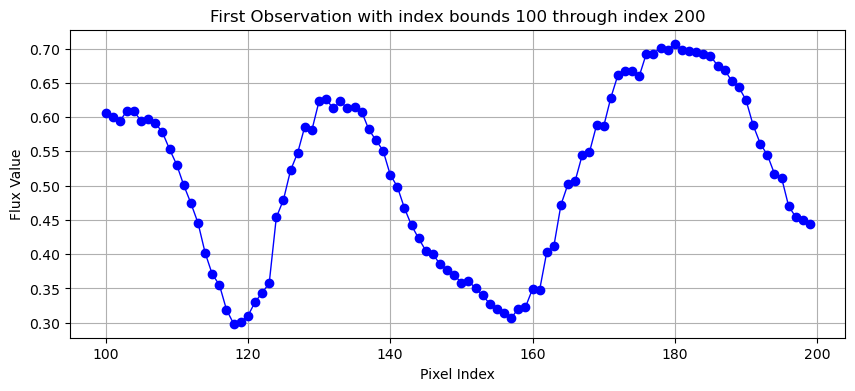

In [103]:
# Plot the first observation's spectral slice from index 0 to 100
index1, index2 = 100, 200
data_array = first_observation[index1 : index2] #colon here

plt.figure(figsize=(10, 4))
plt.plot(range(index1, index2), data_array, marker='o', color='blue', linestyle='-', linewidth=1)
plt.title("First Observation with index bounds " + str(index1) + " through index " + str(index2))
plt.xlabel("Pixel Index")
plt.ylabel("Flux Value")
plt.grid(True)
plt.show()

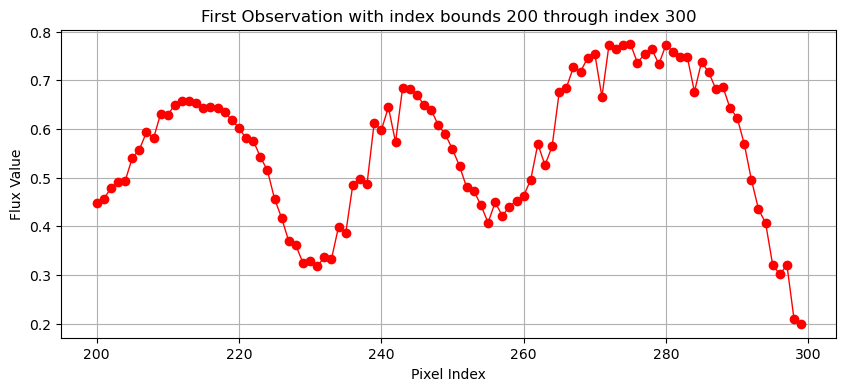

In [104]:
# Plot the first observation's spectral slice from index 100 to 200
index1, index2 = 200, 300
data_array = first_observation[index1 : index2] #colon here

plt.figure(figsize=(10, 4))
plt.plot(range(index1, index2), data_array, marker='o', color='red', linestyle='-', linewidth=1)
plt.title("First Observation with index bounds " + str(index1) + " through index " + str(index2))
plt.xlabel("Pixel Index")
plt.ylabel("Flux Value")
plt.grid(True)
plt.show()

## Notice how the previous code was quite repetitive?

It's easier to use functions for tasks like plotting. The function below takes a single daily spectrum and a pixel range, so it works with either the 36-day full spectra or the 340-day KITCAT selection.

In [105]:
def plot_spectral_slice(data_array, start_idx, end_idx, observation_name, stats=True, color='orange'):
    # it's generally okay to use AI for doc strings, which explains what a function does.
    '''
    Plots a slice of a 1D observation array, with options to compute and overlay
    key statistics (min, max, mean) on the visualization using calculate_range_stats.

    Parameters:
    data_array (numpy.ndarray): The 1D array representing a single spectrum/observation.
    start_idx (int): The starting index of the slice (inclusive).
    end_idx (int): The ending index of the slice (exclusive).
    stats (bool): If True, computes and displays the min, max, and mean statistics on the plot.
    '''
    # Slice the data based on the indices
    data_slice = data_array[start_idx:end_idx]
    indices = np.arange(start_idx, end_idx)

    # Create the plot
    plt.figure(figsize=(12, 5))
    plt.plot(indices, data_slice, marker='o', color=color, linestyle='-', linewidth=1, label='Spectrum')

    if stats:
        # Call our pre-existing calculate_range_stats function!!!
        # Pay attention to the function call here
        stats_array = calculate_range_stats(data_array, start_idx, end_idx)
        min_val, max_val, mean_val = stats_array[0], stats_array[1], stats_array[2]

        # Plot horizontal line for the mean
        plt.axhline(mean_val, color='green', linestyle='--', linewidth=1.5, label=f'Mean ({mean_val:.3f})')

        # Plot min and max markers, need to get the index here.
        min_idx = indices[np.argmin(data_slice)]
        max_idx = indices[np.argmax(data_slice)]
        plt.scatter(min_idx, min_val, color='blue', s=100, zorder=5, label=f'Min ({min_val:.3f})')
        plt.scatter(max_idx, max_val, color='red', s=100, zorder=5, label=f'Max ({max_val:.3f})')

    # Styling
    plt.title(f"{observation_name} Observation with index bounds {start_idx} through index {end_idx}")
    plt.xlabel("Pixel Index")
    plt.ylabel("Flux Value")
    plt.grid(True)
    plt.legend(loc='best')
    plt.show()

--- Statistics for Index Range [100:200] ---
Minimum Value : 0.298535
Maximum Value : 0.706979
Mean Value    : 0.513768



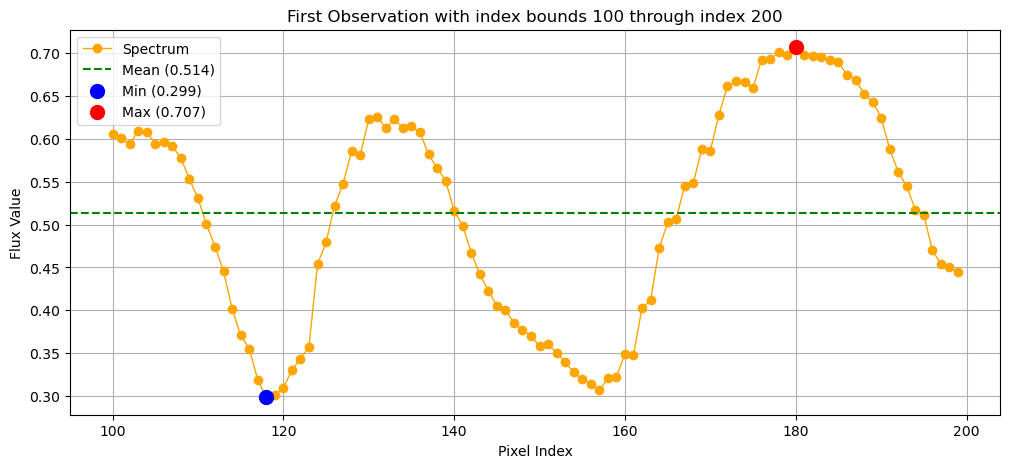

In [106]:
# --- Demo execution of the new function ---
plot_spectral_slice(first_observation, 100, 200, 'First', stats=True)

## Let's look at another observing day! Day #27

For the full spectra, the first row is October 13, 2023 and the last row is November 26, 2023. For KITCAT, those dates are December 15, 2022 and May 15, 2024.

(36, 317104)
--- Statistics for Index Range [100:200] ---
Minimum Value : 0.291896
Maximum Value : 0.702510
Mean Value    : 0.513371



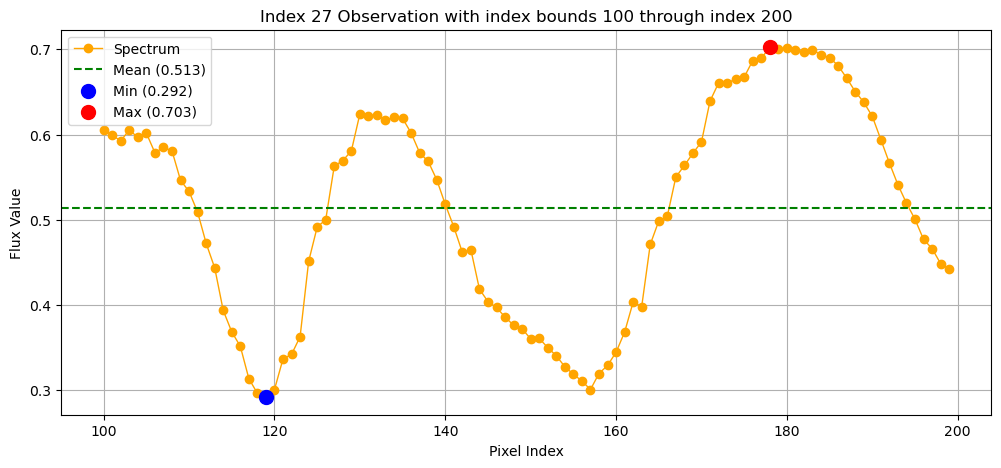

In [107]:
print(data.shape)
observation_index = 27      #you can change this number
random_observation = data[observation_index]
plot_spectral_slice(random_observation, 100, 200, f'Index {observation_index}', stats=True)

# 4.0 Extending the analysis to wavelength and time

## ----------------------------------------------------------------------------------------------

## Great work so far! There are two more things to cover

## 1. We have been using pixel indices, but each column has a wavelength.

## 2. Each row also has an observing date, so we can produce a time series to explore variability.

## ----------------------------------------------------------------------------------------------

## 4.1) First we load the wavelength grid selected earlier

The full spectra use `support_files/wavelengths.npy`, while KITCAT uses `support_files/waves_kitcat.txt`.  The wavelengths are in angstroms

In [ ]:
# Load the wavelength array

wavelength_path = os.path.join(support_path, wavelength_filename) ##this is the path to the wavelengh array
print('1) the wavelength path is', wavelength_path)
if use_kitcat:
    wavelengths = np.loadtxt(wavelength_path)
else:
    wavelengths = np.load(wavelength_path)


if len(wavelengths) != data.shape[1]:
    print('something is wrong, double check the data you loaded?')
    raise ValueError("The wavelength grid must match the number of columns in data.")

print("2) Wavelength Array Shape:", wavelengths.shape)
print("3) Wavelength range (angstroms):", wavelengths.min(), wavelengths.max())
print('4) The first wavelength is:', wavelengths[0])
print('5) The first 10 wavelength values in angstroms are:')
print(wavelengths[0:10])

1) the wavelength path is support_files/wavelengths.npy
2) Wavelength Array Shape: (317104,)
3) Wavelength range (angstroms): 3890.0001582732602 6599.9981230528965
4) The first wavelength is: 3890.0001582732602
5) The first 10 wavelength values in angstroms are:
[3890.00015827 3890.00664352 3890.01312877 3890.01961403 3890.02609931
 3890.03258459 3890.03906989 3890.0455552  3890.05204052 3890.05852584]


## Let's plot the data in wavelength space

We still choose the slice using pixel indices, just to stay familiar. Keep in mind that adjacent KITCAT entries can be separated by gaps in wavelength; a line drawn between them does not mean we observed the missing pixels.

In [109]:
def plot_spectral_slice_wavelength(data_array, start_idx, end_idx, observation_name, stats=True, color='orange'):
    '''
    Plots a slice of a spectrum against wavelength in angstroms.
    Uses the loaded wavelengths array for the x-axis.

    Parameters:
    data_array (numpy.ndarray): The 1D array representing a single spectrum.
    start_idx (int): The starting pixel index (inclusive).
    end_idx (int): The ending pixel index (exclusive).
    observation_name (str): The observation label used in the plot title.
    stats (bool): If True, prints and marks the minimum, maximum, and mean.
    color (str): Line color for the spectrum.
    '''
    # Slice both data and wavelengths using the pixel indices
    data_slice = data_array[start_idx:end_idx]
    wavelength_slice = wavelengths[start_idx:end_idx]

    # Plot in wavelength space
    plt.figure(figsize=(12, 5))
    plt.plot(wavelength_slice, data_slice, marker='o', color=color, linestyle='-', linewidth=1, label='Spectrum')
    #plt.scatter(wavelength_slice, data_slice, marker='o', color=color, ) #linestyle='-', linewidth=1, label='Spectrum')

    if stats:
        stats_array = calculate_range_stats(data_array, start_idx, end_idx)
        min_val, max_val, mean_val = stats_array[0], stats_array[1], stats_array[2]

        # Plot the mean line and min/max markers in wavelength coordinates
        plt.axhline(mean_val, color='green', linestyle='--', linewidth=1.5, label=f'Mean ({mean_val:.3f})')
        min_wl = wavelength_slice[np.argmin(data_slice)] ##--> argmin(dataslice) ; 125, and then we do wavelength_slice[125]
        max_wl = wavelength_slice[np.argmax(data_slice)]
        plt.scatter(min_wl, min_val, color='blue', s=100, zorder=5, label=f'Min ({min_val:.3f})')
        plt.scatter(max_wl, max_val, color='red', s=100, zorder=5, label=f'Max ({max_val:.3f})')

    plt.title(f"{observation_name} Observation ({start_idx} to {end_idx} in index Space)")
    plt.xlabel("Wavelength (angstroms)")
    plt.ylabel("Flux Value")
    plt.grid(True)
    plt.legend(loc='upper right', fontsize=14)
    plt.show()

--- Statistics for Index Range [100:200] ---
Minimum Value : 0.298535
Maximum Value : 0.706979
Mean Value    : 0.513768



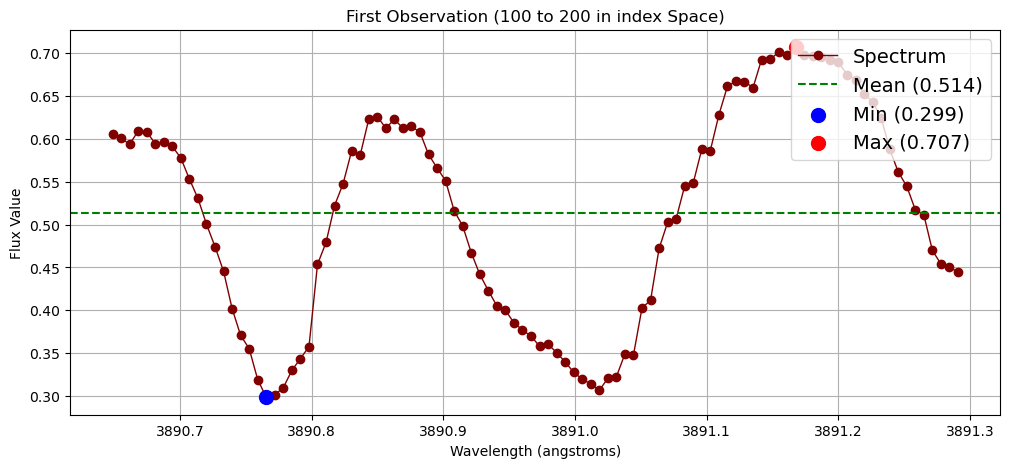

In [110]:
# Quick test run
plot_spectral_slice_wavelength(first_observation, 100, 200, 'First', stats=True,  color='maroon')

## 4.2) Now let's make a time series

An absorption line has lower flux than the nearby continuum. Following the flux in a wavelength region across observing days can help us explore how the spectrum changes.

Let's load the date table selected earlier: `spectra_time_df.csv` for the 36 full spectra, or `kitcat_time_df.csv` for the 340 KITCAT spectra. Its rows are already in the same order as `data`, so we should keep that order.

The columns are `filename` (the daily-bin identifier), `date`, `mjd`, `jd`, `n_observations`, and `snr`.

In [111]:
# Load the time dataset for the same 36 full-spectrum days or 340 KITCAT days
time_pathname = os.path.join(support_path, time_filename)
print('1) the time filepath is', time_pathname)
time_df = pd.read_csv(time_pathname, parse_dates=['date'])

if len(time_df) != data.shape[0]:
    raise ValueError("The time table must match the number of rows in data.")

# The time is stored under 'date', 'mjd', and 'jd'; let's display the columns first to check
print("2) Columns in DataFrame:", list(time_df.columns))
print("3) Number of observing days:", len(time_df))
print("4) Date range:", time_df['date'].min(), "through", time_df['date'].max())

display(time_df.head(20))       # Pandas is something useful to use for analyzing tables of data rather than an array
# display(time_df.tail(20))

1) the time filepath is support_files/spectra_time_df.csv
2) Columns in DataFrame: ['filename', 'date', 'mjd', 'jd', 'n_observations', 'snr']
3) Number of observing days: 36
4) Date range: 2023-10-13 18:53:33.205000 through 2023-11-26 18:50:58.750000


,filename,date,mjd,jd,n_observations,snr
0,daily_bin_0714,2023-10-13 18:53:33.205,60230.787190,2.460231e+06,80,2330.620794
1,daily_bin_0715,2023-10-14 18:52:43.450,60231.786614,2.460232e+06,80,2309.482806
2,daily_bin_0716,2023-10-15 18:53:12.806,60232.786954,2.460233e+06,80,2331.176617
3,daily_bin_0717,2023-10-16 18:40:47.814,60233.778331,2.460234e+06,80,2328.123855
4,daily_bin_0718,2023-10-17 19:23:33.427,60234.808026,2.460235e+06,80,2312.932963
5,daily_bin_0719,2023-10-18 18:53:11.677,60235.786941,2.460236e+06,80,2311.180911
6,daily_bin_0720,2023-10-19 18:53:15.883,60236.786989,2.460237e+06,80,2326.556251
7,daily_bin_0721,2023-10-20 18:53:18.103,60237.787015,2.460238e+06,80,2313.455353
8,daily_bin_0722,2023-10-21 18:52:22.966,60238.786377,2.460239e+06,80,2318.858787
9,daily_bin_0723,2023-10-22 18:53:15.349,60239.786983,2.460240e+06,80,2339.357369


## For convenience, let's measure time relative to the first observing day

The time tables provide `mjd` in days. Subtracting its minimum gives `relative_days`, starting at zero. The full spectra span about 44 elapsed days, and KITCAT spans about 517 elapsed days. Those spans are longer than the 36 and 340 observing days because there are gaps in the observations.

In [112]:
# Calculate the relative time in days using the explicit 'mjd' column
time_df['relative_days'] = time_df['mjd'] - time_df['mjd'].min()
display(time_df[['mjd', 'relative_days']].head())

,mjd,relative_days
0,60230.787190,0.000000
1,60231.786614,0.999424
2,60232.786954,1.999764
3,60233.778331,2.991141
4,60234.808026,4.020836


## Here is the task: First we filter by wavelength then by observing day

Let's compute the minimum flux between 5000 and 5100 angstroms for each selected observing day, then plot it as a time series.

The minimum is taken over the available pixels in that wavelength range. 

First, let's build the standalone plot without using a function. Your job will be to make the function!

The wavelength grids are sorted, so we can locate the first and last retained pixels between 5000 and 5100 angstroms and use them as slice boundaries. The year filter includes both endpoints and starts with every available observing day.

In [120]:
# 1. Find pixel index boundaries by locating where wavelengths are between 5000 and 5100
matching_indices = np.where((wavelengths >= 5000) & (wavelengths <= 5100))[0]
if len(matching_indices) == 0:
    raise ValueError("There are no wavelength pixels in the selected range.")
start_idx = matching_indices[0]
end_idx = matching_indices[-1] + 1
print(f"1) Wavelength 5000-5100 Angstroms corresponds to pixel indices: [{start_idx}:{end_idx}]")


# 2. Find observation indices within the relative time range
start_day, end_day = 5, 27          # Note, you probably want to expand this time range a lot, to something like 5 and 200, if you're using the KITCAT spectrum.
relative_days = time_df['relative_days'].values
filtered_indices = np.where((relative_days >= start_day) & (relative_days <= end_day))[0]
print(f'2) These are the first 20 indices for the observing days we are interested in', filtered_indices[0:20])
print(f"3) Number of observing days in that range: {len(filtered_indices)}")

1) Wavelength 5000-5100 Angstroms corresponds to pixel indices: [150574:162452]
2) These are the first 20 indices for the observing days we are interested in [ 6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]
3) Number of observing days in that range: 19


## Next we iterate over the observing days

These are row indices that connect the selected dates to their daily spectra. For each row, we extract the retained pixels between 5000 and 5100 angstroms and compute the minimum flux. 

In general, it will probably correspond to the minimum of a single absorption line in the wavelength range, so we are tracking variability of that line

In [114]:
# 3. Extract minimum flux for each of these observing days using the same statistic as our stats function
min_fluxes = []

for idx in filtered_indices:
    observation_data = data[idx]                                        #this is from our original data array from earlier!! we are picking the day
    observation_selection = observation_data[start_idx:end_idx]         #here we are picking the wavelength range
    min_value = np.min(observation_selection)                           #extract min value
    min_fluxes.append(min_value)                                        #add that min value to our time series

min_fluxes = np.array(min_fluxes)

## Now we plot this time series

There is one point per selected observing day: 36 points for the full spectra or 340 for KITCAT when all available years are included. The calendar-date axis preserves the gaps between observing days; the connecting lines just help us follow the sequence.

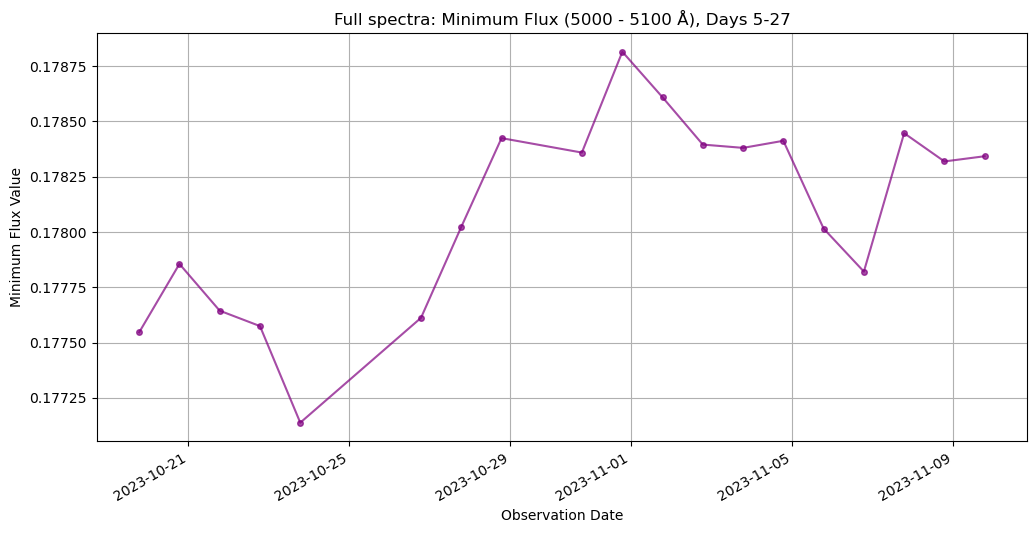

In [115]:
# 4. Plot the time series of minimum flux values using calendar dates
plt.figure(figsize=(12, 6))

# Use the 'date' column as actual datetime objects for beautiful date formatting on the x-axis
observation_dates_for_plotting = time_df.iloc[filtered_indices]['date']
calendar_dates = pd.to_datetime(observation_dates_for_plotting)

plt.plot(calendar_dates, min_fluxes, marker='o', linestyle='-', color='purple', markersize=4, alpha=0.7)
plt.title(f"{data_name}: Minimum Flux (5000 - 5100 Å), Days {start_day}-{end_day}")
plt.xlabel("Observation Date")
plt.ylabel("Minimum Flux Value")
plt.grid(True)
plt.gcf().autofmt_xdate() # Automatically rotates and formats the date labels nicely
plt.show()



# 5.0 Homework/Exercises

## -------------------------------------------

## 5.1) Task 1: Create a function that generalizes the procedure we just did

The function should take `start_day` and `end_day` as arguments, measured in days since the first observing day. Use `time_df['relative_days']` and `np.where` to select the observations between those times, including both endpoints, just like we did above:

For example, `start_day=5` and `end_day=27` select observations between 5 and 27 elapsed days after the first observation. These values are relative times, not row indices.

The starting and ending wavelengths should also be arguments. Within that wavelength range, compute the minimum flux for each selected observing day, then plot those values against their calendar dates. Use the same `filtered_indices` to select the spectra from `data` and get the actual dates from `time_df.iloc[filtered_indices]['date']`.

The function should use the currently loaded `data`, `wavelengths`, and `time_df`, so changing `use_kitcat` and rerunning the notebook changes the data used by the function too. 

It's a good idea to add a simple check for a selection with no observing days or no wavelength pixels.

## Bonus challenge: Start with the minimum, then try other statistics

You can compute the mean, maximum, or standard deviation within the wavelength range instead. Add a `method` argument, for example `method='mean'`, to choose the quantity computed for each observing day. Organize your function using `# data wrangling`, `# calculations`, and `# plotting` comments so each step is easy to follow. The function signature is given below.

In [116]:
def plot_minimum_time_series(start_day, end_day, wave_start, wave_end, method='min', color='red'):
    '''
    Plots a time series of a computed metric (min, max, mean, std) within a specified
    wavelength range across a selected range of relative times in days.

    Parameters:
    start_day (float): The starting time in days since the first observation (inclusive).
    end_day (float): The ending time in days since the first observation (inclusive).
    wave_start (float): The starting wavelength boundary in Angstroms.
    wave_end (float): The ending wavelength boundary in Angstroms.
    method (str): The statistical method to apply: 'min', 'max', 'mean', or 'std'.
    color (str): Line color for the plot.
    '''
    ## Write your code here:


    # data wrangling, manage your data here

    #calculations, write your calculations here

    # plotting, create your plotting code here
    return None

## If your function works, it should reproduce the plot above

After filling in the function, run the example below. It uses the same `start_day` and `end_day` limits as the standalone plot above, so it works for either data selection. With the current example, those limits are 5 and 27 days after the first observation.

In [117]:
plot_minimum_time_series(start_day=start_day, end_day=end_day, wave_start=5000, wave_end=5100, method='min', color='purple')

## 5.2) Task 2: Identify which wavelength ranges show the largest changes in flux relative to the average spectrum over the selected observing period

This task is best suited for the kitcat data, since there are more observing dates there.

First, write a function (or write the baby steps) that computes the master spectrum by averaging the flux at each wavelength pixel across all loaded observing days: 36 for the full spectra, or 340 for KITCAT. Treat this as our reference spectrum and plot it over the available wavelength range, approximately 3890–6600 angstroms for the full spectra or 3911–6596 angstroms for KITCAT. You can make the function below plot the master spectrum automatically each time it's called.

For each observing day, subtract the master spectrum from the observed daily spectrum, pixel by pixel: `residual = observed spectrum - master spectrum`. Each day will now have its own residual spectrum. We are using only the flux arrays here, without uncertainty weighting in this exercise.

Next, divide a selected wavelength range into bins of width `W` angstroms. The wavelength limits and bin width should be function arguments. For example, 4000–6000 angstroms with `W = 50` gives 40 bins (`2000/50 = 40`). Select pixels by their wavelengths, since KITCAT has gaps. If a bin has no retained pixels, skip it or mark its result as `NaN`. If you compute np.std on an array, you may get NaN, so you might need to implement np.nanstd() for example. 

For each observing day and each bin, compute the standard deviation of the residual flux values across the wavelength pixels inside that bin. This produces one value per bin per day.

Then, for each bin, average those standard deviations across observing days. Compute the standard deviation across wavelength pixels first, then average the resulting values over time.

Write a function that performs this analysis and plots the results. Use the central wavelength of each bin on the x-axis and its time-averaged residual standard deviation on the y-axis. Identify the bin with the largest average value.

Interpret this metric as the typical amount of wavelength-dependent variation within each bin relative to the master spectrum. This calculation obviously depends on the binning size and the observing dates, so keep that in mind when comparing the KITCAT data and the full spectrum data.

In [118]:
def analyze_spectral_variability_bins(wave_start, wave_end, bin_width):
    '''
    Performs a binned variability analysis on residual spectra to find which regions
    show the largest shape changes relative to the average master spectrum.

    Parameters:
    wave_start (float): The starting wavelength of the analysis region in Angstroms.
    wave_end (float): The ending wavelength of the analysis region in Angstroms.
    bin_width (float): The width W of each wavelength bin in Angstroms.

    Returns:
    dict: A dictionary containing bin centers, time-averaged residual standard deviations,
          and the properties of the bin showing maximum variability.
    '''
    # Break down the steps into parts!
    # Use comments to highlight and break down specific steps, and feel free to print/plot as many things as you need within the function to accomplish your task

    return None

## If your function works, congrats! Please feel free to email me your results! aryan.gupta@princeton.edu

In [119]:
# Example call to perform the binned variability analysis
# This analyzes the range 4000 to 6000 Angstroms using bins of width 50 Angstroms (resulting in 40 bins)
analysis_results = analyze_spectral_variability_bins(wave_start=4000, wave_end=6000, bin_width=50) #angstroms here.